# Regresión: GLM Poisson

### Imports y Configuración

In [1]:
import sys
sys.path.append("/workspace/src")

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown

from EstiloGraficos import aplicar_estilo

# Misma paleta y estilo que el dashboard (components/plotly_theme.py)
aplicar_estilo()

# Textos largos completos en las tablas (criterio de selección, hiperparámetros)
pd.set_option("display.max_colwidth", None)

from ModeladoRegresion import (
    SEED, USAR_GPU, GPU_DISPOSITIVOS, NOMBRES_REG, VARIANTES, N_ITER_REG, RUTA_FASE1_REG,
    cargar_split, separar_x_y_reg, crear_cv_reg, resumen_target, dispositivo_reg, describir_espacio_reg,
    ejecutar_fase1_reg, formatear_tabla_cv_reg, tabla_hiperparametros_reg,
    elegir_variante, guardar_fase1_reg, formatear_hiperparametros,
    pruebas_poisson, interpretar_razones, probabilidades_conteo, graficar_frecuencias_conteo,
)

CLAVE = "poisson"

In [2]:
pd.Series({
    "USAR_GPU": USAR_GPU,
    "GPU detectada por librería": ", ".join(f"{lib}: {disp}" for lib, disp in GPU_DISPOSITIVOS.items() if disp) or "ninguna",
    "Dispositivo de entrenamiento": dispositivo_reg(CLAVE),
}, name=NOMBRES_REG[CLAVE]).to_frame()

,GLM Poisson
USAR_GPU,False
GPU detectada por librería,ninguna
Dispositivo de entrenamiento,CPU


### Datos: Split y Folds

In [3]:
df = pd.read_csv('/workspace/data/raw/screen_time_mental_health.csv')

df_train, _ = cargar_split(df)   # el test no se usa en esta fase
X_train, y_train = separar_x_y_reg(df_train)
cv = crear_cv_reg(SEED)

resumen_target(y_train)

,Filas,Media,Mediana,DE,Asimetría,Ceros (%),BDI ≥ 14 (%)
Conjunto,,,,,,,
Train,3848,7.3,5.0,7.75,1.9,10.5,16.4


### Variante del Target: Solo Nativo

En este modelo **solo se usa el target nativo**, sin sqrt ni log1p:

- El GLM Poisson ya es un modelo de **conteos**: supone $y \sim \text{Poisson}(\mu)$ con $\log \mu = x\beta$. El enlace log ya hace el trabajo que se buscaba con las transformaciones (efectos multiplicativos, predicciones siempre positivas y una pérdida que tolera la cola derecha).
- Transformar el target rompería el modelo: $\sqrt{y}$ y $\log(1+y)$ no son conteos enteros, así que la distribución Poisson dejaría de tener sentido.
- La predicción $e^{x\beta}$ ya está en la escala de la media del BDI, así que no hay sesgo de retransformación ni hace falta smearing.

La predicción se recorta a $[0, 63]$ como en todos los modelos (en la práctica solo puede activarse el límite superior).

### Espacio de Búsqueda

`PoissonRegressor` penaliza los coeficientes con L2. Se exploraron 10 valores de `alpha` en escala logarítmica entre 1e-4 (prácticamente el GLM sin penalizar) y 1e1.

In [4]:
describir_espacio_reg(CLAVE).style.set_caption(f"Combinaciones: {N_ITER_REG[CLAVE]}")

,Valores
Hiperparámetro,
alpha,log-uniforme entre 0.0001 y 10


### Validación Cruzada

`RandomizedSearchCV` **solo sobre el train**, con los mismos folds y `scoring="neg_root_mean_squared_error"`. El RMSE, el MAE y el R² se calculan en puntos BDI.

In [5]:
tabla, pipelines, hiperparametros = ejecutar_fase1_reg(CLAVE, X_train, y_train, cv, seed=SEED)

✓ Nativo             RMSE = 7.0027 ± 0.4541  R² = 0.1762  (4 s)


In [6]:
vista = formatear_tabla_cv_reg(tabla)
vista["Tiempo (s)"] = tabla["Tiempo (s)"].round(0)
display(vista.rename(index=VARIANTES))
tabla_hiperparametros_reg(hiperparametros)

,RMSE,MAE,R²,Tiempo (s)
Variante,,,,
Nativo,7.003 ± 0.454,4.969 ± 0.188,0.176 ± 0.024,4.0


,alpha
Variante,
Nativo,0.4571


El GLM Poisson obtiene un RMSE de 7.003 ± 0.454 y un R² de 0.176 ± 0.024, peor que la regresión lineal (6.900 y 0.201). El tuning eligió una penalización L2 moderada (`alpha` = 0.457).

Que un modelo pensado para conteos prediga peor la media que OLS indica que el efecto multiplicativo del enlace log no describe mejor los datos que el aditivo. En `reg_lineal`, la curva LOWESS de los residuos descendía en los ajustados altos (la relación es algo cóncava), justo lo contrario de lo que supone el enlace log. Al exponenciar, las predicciones de los adolescentes con varios factores de riesgo crecen demasiado, y eso penaliza mucho el RMSE.

### Selección del Mejor Modelo GLM Poisson

Con una sola variante, la ganadora es la nativa con sus mejores hiperparámetros.

In [7]:
variante_ganadora, explicacion = elegir_variante(tabla)

pd.Series({
    "Variante ganadora": VARIANTES[variante_ganadora],
    "RMSE de CV": f"{tabla.loc[variante_ganadora, 'RMSE media']:.4f} ± {tabla.loc[variante_ganadora, 'RMSE DE']:.4f}",
    "MAE de CV": f"{tabla.loc[variante_ganadora, 'MAE media']:.4f} ± {tabla.loc[variante_ganadora, 'MAE DE']:.4f}",
    "R² de CV": f"{tabla.loc[variante_ganadora, 'R² media']:.4f} ± {tabla.loc[variante_ganadora, 'R² DE']:.4f}",
    "Hiperparámetros": formatear_hiperparametros(hiperparametros[variante_ganadora]),
    "Criterio": explicacion,
}, name=NOMBRES_REG[CLAVE]).to_frame()

,GLM Poisson
Variante ganadora,Nativo
RMSE de CV,7.0027 ± 0.4541
MAE de CV,4.9692 ± 0.1885
R² de CV,0.1762 ± 0.0240
Hiperparámetros,alpha=0.4571
Criterio,Se elige 'Nativo': tiene el menor RMSE medio de CV (7.0027 ± 0.4541) y ninguna opción más simple queda a menos de una desviación estándar (0.4541).


La elección es directa: el modelo guardado es el `PoissonRegressor` con `alpha` = 0.457.

### Guardado

In [8]:
ganador = guardar_fase1_reg(
    CLAVE, tabla, variante_ganadora, pipelines[variante_ganadora],
    hiperparametros[variante_ganadora], explicacion,
)
print(f"✓ Guardado en {RUTA_FASE1_REG / CLAVE}: resultados_cv.csv, ganador.json y {ganador['archivo']}")

✓ Guardado en /workspace/data/processed/modelado/regresion/fase1/poisson: resultados_cv.csv, ganador.json y poisson_nativo.joblib


## Pruebas de Hipótesis

Se ajusta el GLM Poisson **sin penalizar** con statsmodels sobre **todo el train**, con los predictores preprocesados con el mismo `ColumnTransformer` ajustado en el train (numéricas estandarizadas, `sex` como indicadora `sex_Girl`), más la constante. Nivel de significancia: α = 0.05.

> **Advertencia sobre el tamaño muestral.** Con n ≈ 3,800 las pruebas detectan desviaciones muy pequeñas. Por eso se complementan con tamaños de efecto (razones de tasas, razón de dispersión) y con el gráfico de frecuencias observadas vs. predichas.

In [9]:
pruebas = pruebas_poisson(X_train, y_train)
pruebas["pruebas"]

,Hipótesis nula,Estadístico,p-valor,Conclusión (α = 0.05)
Prueba,,,,
"Razón de verosimilitud vs. nulo (χ², 6 g.l.)",Todos los coeficientes (salvo la constante) son 0,5836.080873,0.000000e+00,Se rechaza H0: al menos un predictor explica el BDI
"Desviación (χ², 3841 g.l.)",El modelo Poisson ajusta bien los datos,21317.893168,0.000000e+00,Se rechaza H0: el Poisson no ajusta bien
χ² de Pearson (3841 g.l.),El modelo Poisson ajusta bien los datos,24271.974938,0.000000e+00,Se rechaza H0: el Poisson no ajusta bien
"Cameron-Trivedi (t, unilateral)",Equidispersión: Var(y) = E(y) (α = 0),20.128207,4.706722e-86,Se rechaza H0: hay sobredispersión (α estimado = 0.623)


Las cuatro pruebas rechazan H0. La razón de verosimilitud frente al modelo nulo (LR = 5836, 6 g.l.) confirma que los predictores explican el BDI. Pero el Poisson no ajusta bien: la desviación (21,318) y el χ² de Pearson (24,272) son 5.5 y 6.3 veces sus 3,841 grados de libertad, y la prueba de Cameron-Trivedi detecta sobredispersión (t = 20.1, α estimado = 0.623). No es un efecto del tamaño muestral: los estadísticos son varias veces su valor esperado.

### Significancia de los Coeficientes

Prueba de Wald (z) de cada coeficiente (H0: β = 0) y prueba de razón de verosimilitud frente al modelo nulo (solo constante), en la primera fila de la tabla anterior.

In [10]:
pruebas["coeficientes"].round(4)

,Coeficiente,EE,Estadístico,p-valor,IC 2.5%,IC 97.5%,Significativo
Variable,,,,,,,
const,1.6699,0.0099,167.9334,0.0000,1.6504,1.6894,True
sleep_quality_index,0.2257,0.0052,43.0140,0.0000,0.2154,0.2360,True
avg_sleep_hours,-0.1040,0.0085,-12.2391,0.0000,-0.1207,-0.0874,True
midsleep_weekend_hours,0.0560,0.0151,3.7171,0.0002,0.0265,0.0855,True
social_jetlag_hours,-0.0006,0.0127,-0.0460,0.9633,-0.0255,0.0243,False
screen_time_index,0.0583,0.0061,9.5344,0.0000,0.0463,0.0702,True
sex_Girl,0.4549,0.0128,35.4068,0.0000,0.4297,0.4801,True


Con los errores estándar del Poisson, cinco de los seis coeficientes son significativos; solo `social_jetlag_hours` no lo es (p = 0.963). Pero esos errores estándar están subestimados por la sobredispersión (ver abajo), así que los estadísticos z (de hasta 43) son exagerados.

### Razones de Tasas

Con enlace log, $e^{\beta}$ es la **razón de tasas**: el factor por el que se multiplica el BDI esperado por cada desviación estándar más del predictor (o al pasar de chicos a chicas en `sex_Girl`), con las demás variables fijas. Un valor de 1.10 significa un BDI esperado un 10% mayor.

In [11]:
display(pruebas["razones_tasas"].round(4))
Markdown(interpretar_razones(pruebas["razones_tasas"]))

,Razón de tasas,IC 2.5%,IC 97.5%,p-valor,Cambio en el BDI esperado (%)
Variable,,,,,
sleep_quality_index,1.2532,1.2404,1.2661,0.0000,25.3180
avg_sleep_hours,0.9012,0.8863,0.9163,0.0000,-9.8791
midsleep_weekend_hours,1.0576,1.0268,1.0893,0.0002,5.7597
social_jetlag_hours,0.9994,0.9749,1.0246,0.9633,-0.0583
screen_time_index,1.0600,1.0474,1.0728,0.0000,6.0001
sex_Girl,1.5760,1.5368,1.6162,0.0000,57.6008


- Por cada desviación estándar más de **sleep_quality_index**, el BDI esperado cambia en **+25.3%** (IC 95%: +24.0% a +26.6%; significativo), con las demás variables fijas.
- Por cada desviación estándar más de **avg_sleep_hours**, el BDI esperado cambia en **-9.9%** (IC 95%: -11.4% a -8.4%; significativo), con las demás variables fijas.
- Por cada desviación estándar más de **midsleep_weekend_hours**, el BDI esperado cambia en **+5.8%** (IC 95%: +2.7% a +8.9%; significativo), con las demás variables fijas.
- Por cada desviación estándar más de **social_jetlag_hours**, el BDI esperado cambia en **-0.1%** (IC 95%: -2.5% a +2.5%; no significativo), con las demás variables fijas.
- Por cada desviación estándar más de **screen_time_index**, el BDI esperado cambia en **+6.0%** (IC 95%: +4.7% a +7.3%; significativo), con las demás variables fijas.
- **sex_Girl**: frente a la categoría de referencia, el BDI esperado cambia en **+57.6%** (IC 95%: +53.7% a +61.6%; significativo), con las demás variables fijas.

En la escala multiplicativa, el sexo es el efecto más grande: las chicas tienen un BDI esperado un 57.6% mayor que los chicos (IC 95%: 53.7% a 61.6%). Por cada desviación estándar más de `sleep_quality_index`, el BDI esperado aumenta un 25.3% (IC: 24.0% a 26.6%). Dormir una desviación estándar más lo reduce un 9.9% (IC: −11.4% a −8.4%), y el tiempo de pantalla y el punto medio del sueño del fin de semana lo aumentan un 6.0% y un 5.8%. El jetlag social no tiene efecto (−0.1%, IC: −2.5% a 2.5%). Los signos coinciden con los de OLS.

### Bondad de Ajuste y Equidispersión

- **Desviación y χ² de Pearson** (H0: el modelo ajusta bien): si el modelo fuera correcto, ambos serían aproximadamente χ² con n − p grados de libertad.
- **Razón de dispersión** = χ² de Pearson / g.l. Bajo el supuesto Poisson (**media = varianza**) debe estar cerca de 1; valores claramente mayores indican **sobredispersión**.
- **Prueba de Cameron-Trivedi**: regresión auxiliar sin constante $\frac{(y-\hat\mu)^2 - y}{\hat\mu} = \alpha\,\hat\mu + \varepsilon$, con H0: α = 0 (equidispersión) frente a α > 0 (varianza $\mu + \alpha\mu^2$, como en la binomial negativa NB2).

Si hay sobredispersión, los **coeficientes siguen siendo consistentes** (la media está bien especificada), pero los **errores estándar del Poisson son demasiado pequeños** (aproximadamente en un factor $\sqrt{\text{dispersión}}$): los p-valores salen artificialmente bajos y los IC demasiado estrechos. La tabla cuasi-Poisson reescala los errores estándar con la dispersión para ver qué conclusiones sobreviven.

In [12]:
pruebas["equidispersion"]

,Equidispersión
Media del BDI (train),7.3000
Varianza del BDI (train),60.0000
χ² de Pearson / g.l. (razón de dispersión),6.3190
α de Cameron-Trivedi,0.6231
Factor de los EE (√ dispersión),2.5140


La varianza del BDI en el train (60.0) es 8.2 veces su media (7.3), y la razón de dispersión del modelo es 6.32. Incluso condicionando en los predictores, la varianza es más de seis veces la que supone el Poisson, así que el supuesto media = varianza no se cumple. Los errores estándar del Poisson son unas 2.5 veces (√6.32) más pequeños de lo que deberían.

In [13]:
pruebas["coeficientes_cuasi"].round(4)

,Coeficiente,EE Poisson,EE cuasi-Poisson,p-valor Poisson,p-valor cuasi-Poisson,Cambia la conclusión
Variable,,,,,,
const,1.6699,0.0099,0.0250,0.0000,0.0000,False
sleep_quality_index,0.2257,0.0052,0.0132,0.0000,0.0000,False
avg_sleep_hours,-0.1040,0.0085,0.0214,0.0000,0.0000,False
midsleep_weekend_hours,0.0560,0.0151,0.0379,0.0002,0.1392,True
social_jetlag_hours,-0.0006,0.0127,0.0319,0.9633,0.9854,False
screen_time_index,0.0583,0.0061,0.0154,0.0000,0.0001,False
sex_Girl,0.4549,0.0128,0.0323,0.0000,0.0000,False


Al reescalar los errores estándar con la dispersión (cuasi-Poisson), los coeficientes no cambian, pero sus errores estándar se multiplican por 2.5. `midsleep_weekend_hours` deja de ser significativo (su p-valor pasa de 0.0002 a 0.139), lo que coincide con OLS. El resto de las conclusiones se mantiene: la calidad del sueño, el sexo, la duración del sueño y el tiempo de pantalla siguen siendo significativos.

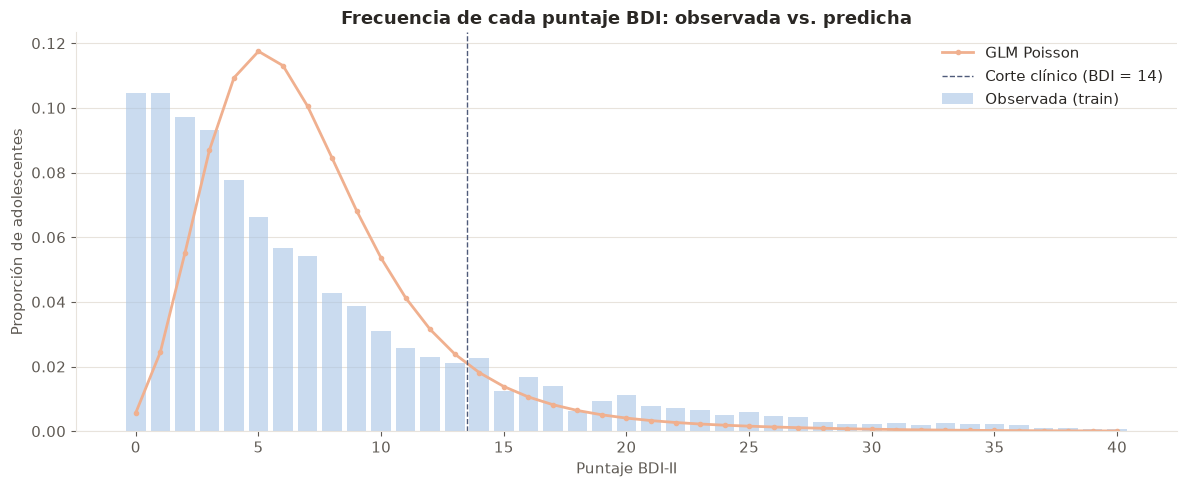

In [14]:
probabilidades = {"GLM Poisson": probabilidades_conteo(pruebas["modelo"].mu)}
fig = graficar_frecuencias_conteo(y_train, probabilidades)
plt.show()

El gráfico muestra con claridad la sobredispersión. El Poisson concentra la probabilidad alrededor de la media: predice casi ningún cero (0.6%, frente al 10.5% observado) y un pico en 4–6 puntos (≈ 11–12%) que en los datos no existe, porque la distribución observada decrece desde 0. En la cola derecha (BDI ≥ 15) se queda corto. Aunque su media condicional es razonable, la distribución que supone no describe el BDI.

### Conclusiones

- El GLM Poisson predice peor que la regresión lineal (RMSE de CV = 7.003 frente a 6.900; R² = 0.176 frente a 0.201).
- Los predictores con efecto son los mismos que en OLS. Las chicas tienen un BDI esperado un 58% mayor y cada desviación estándar de `sleep_quality_index` lo aumenta un 25%.
- El supuesto de equidispersión falla con claridad (razón de dispersión = 6.3; Cameron-Trivedi, p < 0.001). Los coeficientes siguen siendo válidos, pero los errores estándar del Poisson son unas 2.5 veces demasiado pequeños: con la corrección cuasi-Poisson, `midsleep_weekend_hours` deja de ser significativo.
- La distribución Poisson no reproduce la forma del BDI (ni los ceros ni la cola), lo que motiva la binomial negativa.